# Lightweight Cybersecurity for IoT, Edge & Fog Computing
### RT-IoT2022 Dataset · Google Colab Research Notebook

**Research Focus:** Evaluate lightweight security mechanisms under resource-constrained conditions across three simulated computing layers.

| Layer | Example Device | Memory Budget | Latency Target | Feature Budget |
|-------|---------------|---------------|----------------|----------------|
|  **IoT**  | RPi Zero / Sensor Node  | ≤ 32 MB   | < 100 ms | Top 5  features |
|  **Edge** | RPi 4 / Edge Gateway    | ≤ 256 MB  | < 50 ms  | Top 15 features |
|  **Fog**  | Mini PC / Local Server  | ≤ 1024 MB | < 20 ms  | All features    |

**Dataset:** [RT-IoT2022 on Kaggle](https://www.kaggle.com/datasets/supplejade/rt-iot2022real-time-internet-of-things) — Real labelled IoT network traffic  
**Attacks:** DDoS (UDP/TCP/ICMP), SSH Brute Force, ARP Poisoning, NMAP Port Scanning

---
*Flow: Setup -> Dataset -> EDA -> Preprocessing -> Layer Simulation -> Mechanisms -> Benchmarking -> Visualisation -> Summary*


## Section 1: Environment Setup

In [ ]:
!pip install nbconvert

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import time, tracemalloc, psutil, os, glob, warnings, zipfile
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)

# Global plot style
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})
sns.set_style('whitegrid')
np.random.seed(42)

LAYER_COLORS = {'IoT': '#E74C3C', 'Edge': '#27AE60', 'Fog': '#2980B9'}
print("All libraries loaded. Environment ready.")


All libraries loaded. Environment ready.


# New Section

In [ ]:
# Install additional packages not pre-installed in Colab
# Retrieving information on running processes and system utilization (CPU, memory, disks, network, sensors)
!pip install scapy psutil -q
print('Library Installed')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 49.6 MB/s eta 0:00:00
Library Installed


## Section 2: Dataset Loading (RT-IoT2022) & Feature Reduction

In [ ]:

from google.colab import files

# Upload file manually
uploaded = files.upload()

# Get uploaded filename automatically
filename = list(uploaded.keys())[0]

# Load dataset into pandas DataFrame
dataFrame = pd.read_csv(filename)

# Show confirmation
print(f"Uploaded file: {filename}")

# Define the 14 features as requested
selectedColumns = [
    'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot',
    'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'flow_SYN_flag_count',
    'flow_FIN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count',
    'fwd_init_window_size', 'bwd_init_window_size', 'Attack_type'
]

# Create the filtered dataframe
df_lightweight = dataFrame[selectedColumns]

# Save to a new CSV file
outputFile = 'RT_IOT2022_Lightweight.csv'
df_lightweight.to_csv(outputFile, index=False)

print("New CSV file 'RT_IOT2022_Lightweight.csv' has been created successfully.")
print(f"Original columns: {dataFrame.shape[1]} | New columns: {df_lightweight.shape[1]}")



Saving RT_IOT2022.csv to RT_IOT2022 (1).csv
Uploaded file: RT_IOT2022 (1).csv
New CSV file 'RT_IOT2022_Lightweight.csv' has been created successfully.
Original columns: 85 | New columns: 14


## Section 3: Data Loading & Exploratory Analysis

In [ ]:
# Identify label column
labelCandidates = ['Attack_type', 'attack_type', 'Label', 'label', 'class', 'Category']
labelColumns = next((c for c in labelCandidates if c in df_lightweight.columns), None)

if labelColumns is None:
    print("Label column not auto-detected. Columns:", df_lightweight.columns.tolist())
    labelColumns = input("Enter label column name: ").strip()

print(f"Label column: '{labelColumns}'")
print(f"\n=== TRAFFIC CLASSES ({df_lightweight[labelColumns].nunique()} unique) ===")
print(df_lightweight[labelColumns].value_counts().to_string())

# Define normal vs attack
NORMAL_CLASSES = [c for c in ['MQTT_Publish', 'Thing_Speak', 'Wipro_bulb']
                  if c in df_lightweight[labelColumns].unique()]
print(f"\nNormal  : {NORMAL_CLASSES}")
print(f"Attacks : {[c for c in df_lightweight[labelColumns].unique() if c not in NORMAL_CLASSES]}")

df_lightweight['binary_label'] = df_lightweight[labelColumns].apply(lambda x: 'Normal' if x in NORMAL_CLASSES else 'Attack')


Label column: 'Attack_type'

=== TRAFFIC CLASSES (12 unique) ===
Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28

Normal  : ['MQTT_Publish', 'Thing_Speak', 'Wipro_bulb']
Attacks : ['ARP_poisioning', 'DDOS_Slowloris', 'DOS_SYN_Hping', 'Metasploit_Brute_Force_SSH', 'NMAP_FIN_SCAN', 'NMAP_OS_DETECTION', 'NMAP_TCP_scan', 'NMAP_UDP_SCAN', 'NMAP_XMAS_TREE_SCAN']


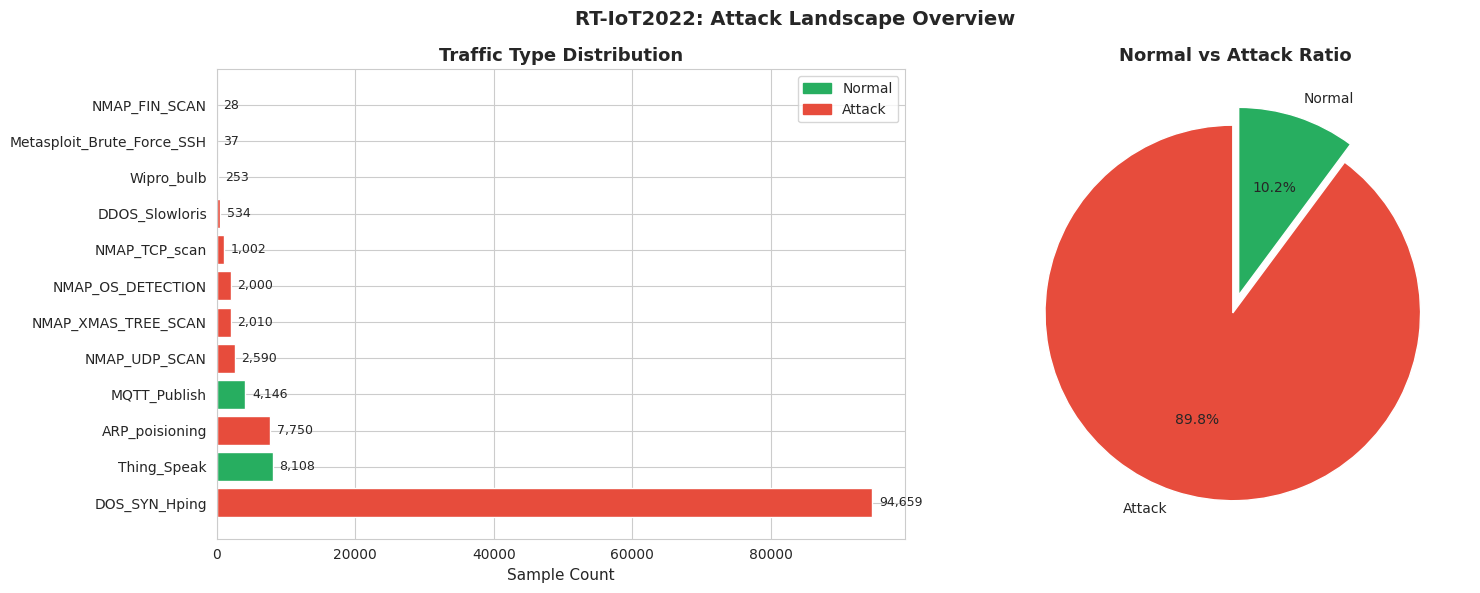

Normal : 12,507  (10.2%)
Attack : 110,610  (89.8%)


In [ ]:
# EDA Plot 1: Class Distribution
vc = df_lightweight[labelColumns].value_counts()
colors = ['#27AE60' if c in NORMAL_CLASSES else '#E74C3C' for c in vc.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart
axes[0].barh(vc.index, vc.values, color=colors, edgecolor='white')
for i, (val, _) in enumerate(zip(vc.values, vc.index)):
    axes[0].text(val + vc.max() * 0.01, i, f'{val:,}', va='center', fontsize=9)
axes[0].set_xlabel('Sample Count')
axes[0].set_title('Traffic Type Distribution', fontweight='bold')
axes[0].legend(handles=[
    mpatches.Patch(color='#27AE60', label='Normal'),
    mpatches.Patch(color='#E74C3C', label='Attack')
])

# Pie chart
bc = df_lightweight['binary_label'].value_counts()
axes[1].pie(bc.values, labels=bc.index, colors=[ '#E74C3C','#27AE60'],
            autopct='%1.1f%%', startangle=90, explode=[0.05, 0.05])
axes[1].set_title('Normal vs Attack Ratio', fontweight='bold')

plt.suptitle('RT-IoT2022: Attack Landscape Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Normal : {(df_lightweight['binary_label']=='Normal').sum():,}  "
      f"({df_lightweight['binary_label'].value_counts(normalize=True)['Normal']*100:.1f}%)")
print(f"Attack : {(df_lightweight['binary_label']=='Attack').sum():,}  "
      f"({df_lightweight['binary_label'].value_counts(normalize=True)['Attack']*100:.1f}%)")


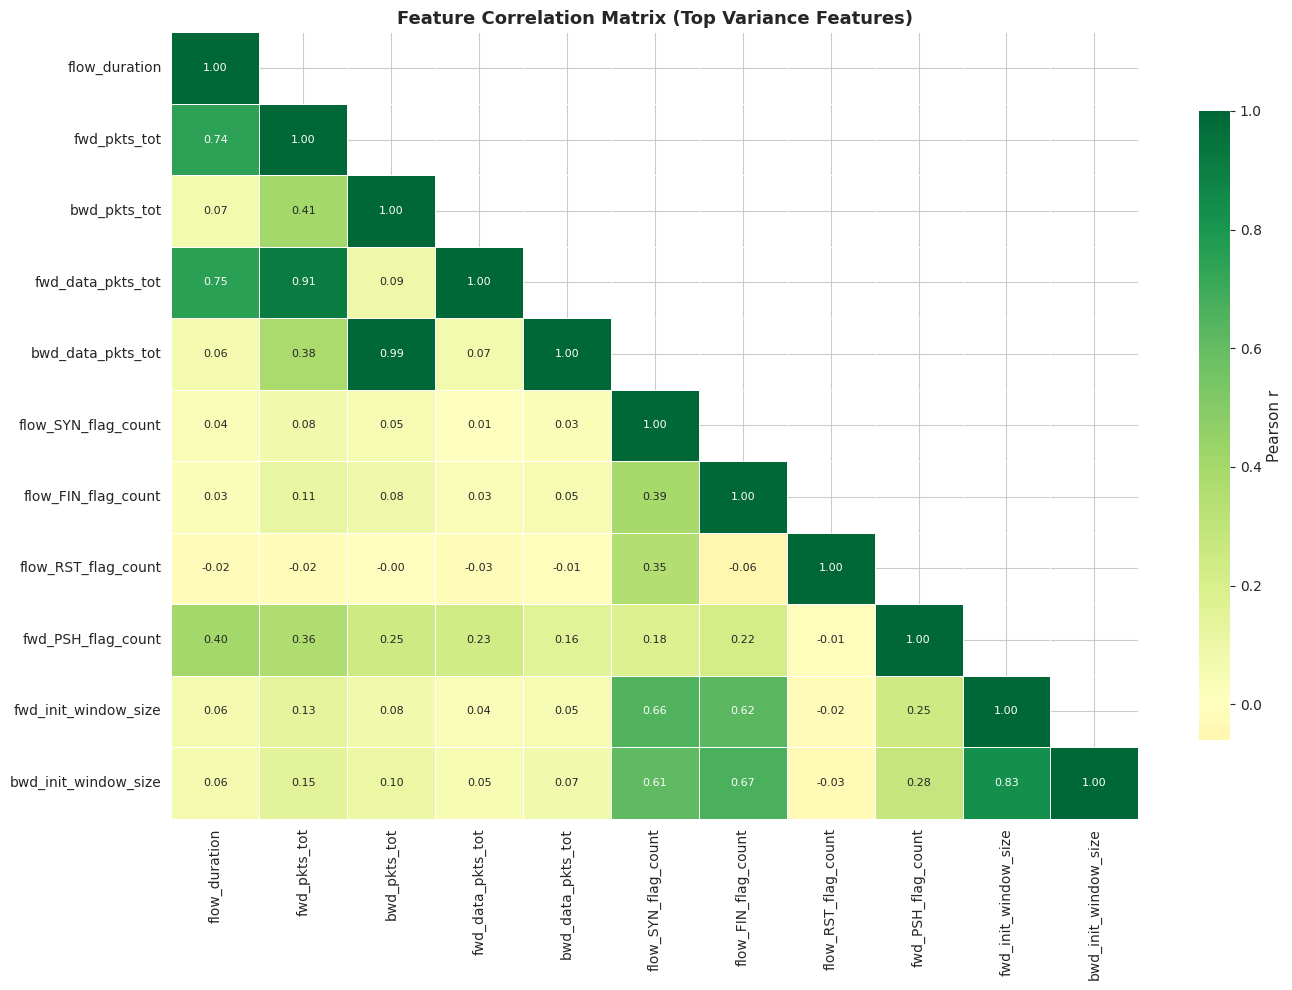

In [ ]:
# EDA Plot 2: Feature Correlation Heatmap
numeric_df = df_lightweight.select_dtypes(include=[np.number])
N = 15
if len(numeric_df.columns) > N:
    numeric_df = numeric_df[numeric_df.var().nlargest(N).index]
    print(f"Showing top {N} numeric features by variance")

corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.4, annot_kws={'size': 8},
            cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}, ax=ax)
ax.set_title('Feature Correlation Matrix (Top Variance Features)', fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


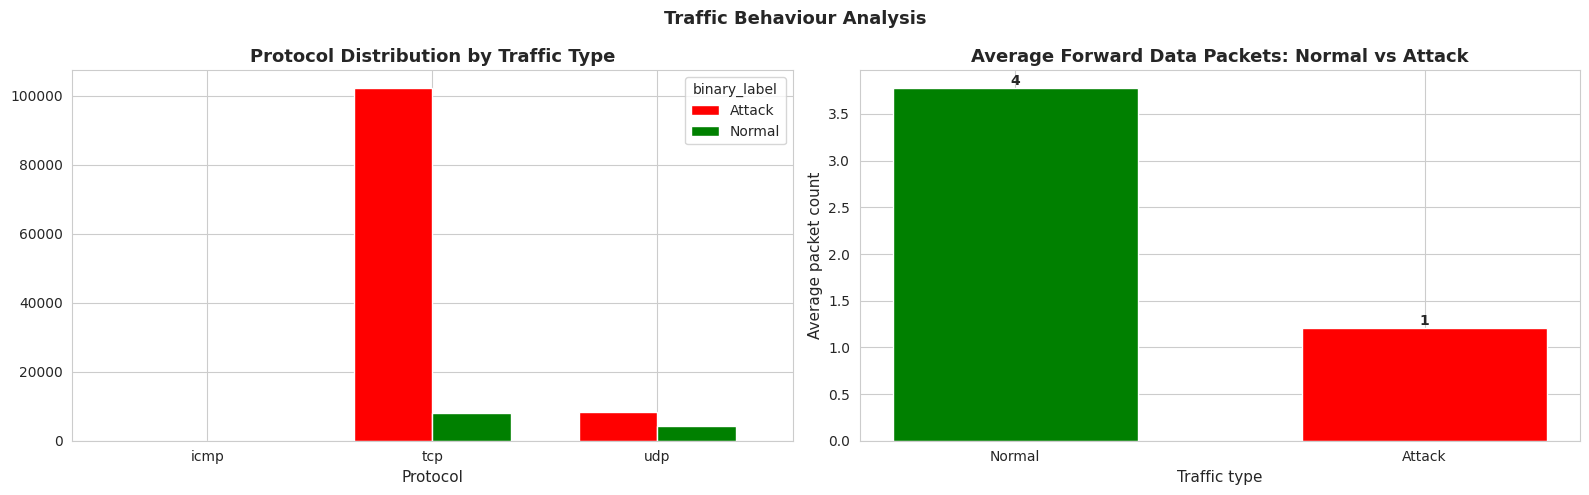

In [ ]:
# EDA Plot 3: Protocol & Byte Distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

if 'proto' in df_lightweight.columns:
    pt = df_lightweight.groupby(['proto', 'binary_label']).size().unstack(fill_value=0)
    pt.plot(kind='bar', ax=axes[0], color=['red', 'green'], edgecolor='white', width=0.7)
    axes[0].set_title('Protocol Distribution by Traffic Type', fontweight='bold')
    axes[0].set_xlabel('Protocol')
    axes[0].tick_params(axis='x', rotation=0)
else:
    axes[0].text(0.5, 0.5, "'proto' column not found", ha='center', va='center')
    axes[0].set_title('Protocol Distribution')

# --- second panel: simple average bar chart, easy to read at a glance ---
if 'fwd_data_pkts_tot' in df_lightweight.columns:
    avg_pkts = df_lightweight.groupby('binary_label')['fwd_data_pkts_tot'].mean()
    avg_pkts = avg_pkts.reindex(['Normal', 'Attack'])  # fixed left-to-right order

    bars = axes[1].bar(
        avg_pkts.index, avg_pkts.values,
        color=['green', 'red'], edgecolor='white', width=0.6
    )
    axes[1].set_title('Average Forward Data Packets: Normal vs Attack', fontweight='bold')
    axes[1].set_xlabel('Traffic type')
    axes[1].set_ylabel('Average packet count')

    # label each bar with its value, so the number is obvious at a glance
    for bar, value in zip(bars, avg_pkts.values):
        axes[1].text(
            bar.get_x() + bar.get_width() / 2, value,
            f'{value:,.0f}', ha='center', va='bottom', fontweight='bold'
        )
else:
    axes[1].text(0.5, 0.5, "'fwd_data_pkts_tot' column not found", ha='center', va='center')
    axes[1].set_title('Byte Distribution')

plt.suptitle('Traffic Behaviour Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('traffic_behaviour.png', dpi=150, bbox_inches='tight')
plt.show()


## Section 4: Data Preprocessing

In [ ]:
## 1. Binary target
df_lightweight['y_binary'] = (df_lightweight['binary_label'] == 'Attack').astype(int)

# 2. Drop label columns only
DROP_CANDIDATES = ['Attack_type', 'binary_label', 'y_binary']
X_raw = df_lightweight.drop(columns=DROP_CANDIDATES).copy()
y = df_lightweight['y_binary'].values

print(f"Features before encoding : {X_raw.shape[1]}")

# 3. Encode categorical columns
le = LabelEncoder()
cat_cols = X_raw.select_dtypes(include=['object', 'bool']).columns.tolist()
print(f"Categorical columns to encode: {cat_cols}")

for col in cat_cols:
    X_raw[col] = le.fit_transform(X_raw[col].astype(str))

# 4. Replace invalid values and fill missing values
X_raw.replace([np.inf, -np.inf], np.nan, inplace=True)
X_raw.fillna(X_raw.median(), inplace=True)

# 5. Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Feature Scaling
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

FEATURE_NAMES = X_raw.columns.tolist()

print("\n Preprocessing complete")
print(f"Features : {X_train.shape[1]}")
print(f"Train    : {X_train.shape[0]:,}")
print(f"Test     : {X_test.shape[0]:,}")
print(f"Attack % (train): {y_train.mean()*100:.1f}%")


Features before encoding : 13
Categorical columns to encode: ['proto', 'service']

 Preprocessing complete
Features : 13
Train    : 98,493
Test     : 24,624
Attack % (train): 89.8%


##Section 5: Three Layer Simulation

Each layer simulating limited compute and specific **target mechanisms**.
Feature selection is driven by ExtraTrees importance scores.


In [ ]:
LAYER_PROFILES = {
    'IoT': {
        'description'      : 'Microcontroller / Sensor node (e.g., RPi Zero)',
        'memory_budget_mb' : 32,
        'latency_target_ms': 100,
        'color'            : '#E74C3C',
        'mechanisms'       : ['RuleIDS', 'NaiveBayes', 'DecisionTree_Shallow']
    },
    'Edge': {
        'description'      : 'Edge gateway / Router (e.g., RPi 4)',
        'memory_budget_mb' : 256,
        'latency_target_ms': 50,
        'color'            : '#27AE60',
        'mechanisms'       : ['StatisticalAD', 'DecisionTree_Deep', 'NaiveBayes']
    },
    'Fog': {
        'description'      : 'Fog node / Local server (e.g., mini PC)',
        'memory_budget_mb' : 1024,
        'latency_target_ms': 20,
        'color'            : '#2980B9',
        'mechanisms'       : ['RandomForest', 'DecisionTree_Deep', 'StatisticalAD']
    }
}
print("Three tier is ready for simulation")


Three tier is ready for simulation


Computing feature importances...


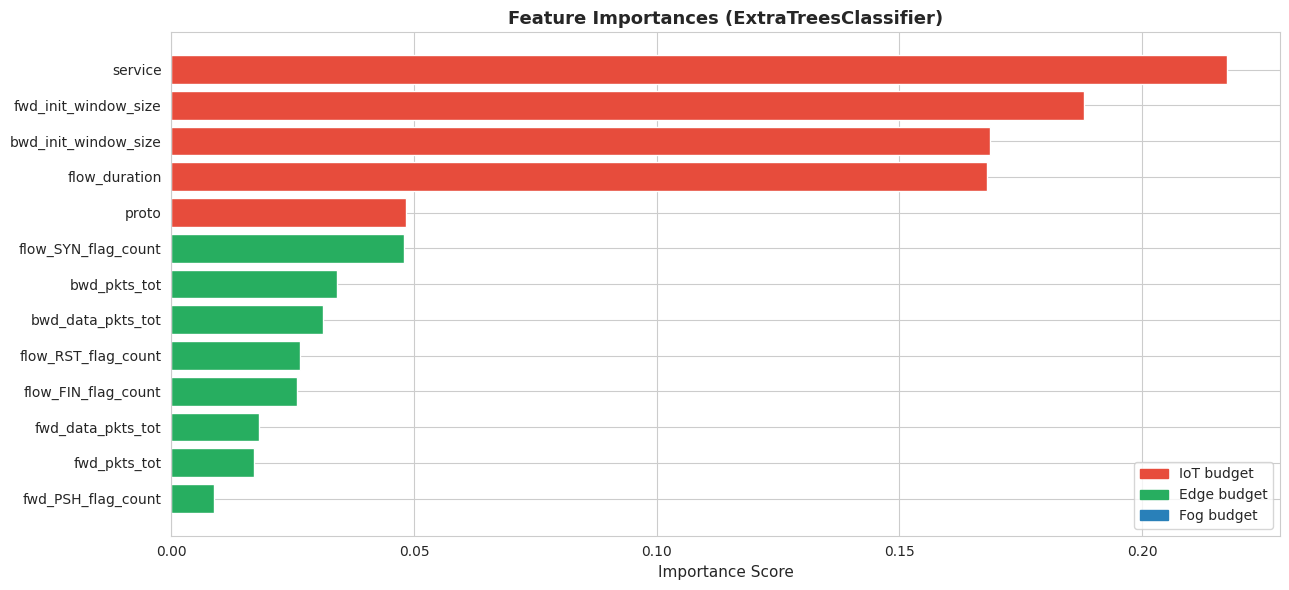


Ranked Features:
1. service
2. fwd_init_window_size
3. bwd_init_window_size
4. flow_duration
5. proto
6. flow_SYN_flag_count
7. bwd_pkts_tot
8. bwd_data_pkts_tot
9. flow_RST_flag_count
10. flow_FIN_flag_count
11. fwd_data_pkts_tot
12. fwd_pkts_tot
13. fwd_PSH_flag_count


In [ ]:
# Feature Importance Analysis Using ExtraTreesClassifier
print("Computing feature importances...")
etc = ExtraTreesClassifier(n_estimators=50, random_state=42, n_jobs=-1)
etc.fit(X_train, y_train)

feat_imp = pd.Series(etc.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
RANKED_FEATURES = feat_imp.index.tolist()

# Plot
fig, ax = plt.subplots(figsize=(13, 6))
top20 = feat_imp.head(20)
bar_colors = [LAYER_COLORS['IoT'] if i<5 else LAYER_COLORS['Edge'] if i<15 else LAYER_COLORS['Fog']
              for i in range(len(top20))]
ax.barh(top20.index[::-1], top20.values[::-1], color=bar_colors[::-1], edgecolor='white')
ax.set_title('Feature Importances (ExtraTreesClassifier)', fontweight='bold')
ax.set_xlabel('Importance Score')
ax.legend(handles=[
    mpatches.Patch(color='#E74C3C', label='IoT budget'),
    mpatches.Patch(color='#27AE60', label='Edge budget'),
    mpatches.Patch(color='#2980B9', label='Fog budget')
], loc='lower right')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nRanked Features:")
for i, f in enumerate(RANKED_FEATURES, 1):
    print(f"{i}. {f}")


In [ ]:
#Layer Dataset Preparation
layer_datasets = {}

for layer in LAYER_PROFILES.keys():

    layer_datasets[layer] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'n_features': X_train.shape[1]
    }

    print(f"[{layer}] Train: {X_train.shape} | Test: {X_test.shape}")


[IoT] Train: (98493, 13) | Test: (24624, 13)
[Edge] Train: (98493, 13) | Test: (24624, 13)
[Fog] Train: (98493, 13) | Test: (24624, 13)


## Section 6: Lightweight Security Mechanisms

| # | Mechanism | Type | Target Layer |
|---|-----------|------|-------------|
| 1 | **Rule-Based IDS** | Threshold / signature | IoT |
| 2 | **Statistical Anomaly Detection** | Z-score profile | Edge |
| 3 | **Naive Bayes** | Probabilistic ML | IoT / Edge |
| 4 | **Decision Tree (shallow)** | Supervised ML — depth 4 | IoT |
| 5 | **Decision Tree (deep)** | Supervised ML — depth 12 | Edge / Fog |
| 6 | **Random Forest** | Ensemble ML | Fog |


In [ ]:
# ===================================
# MECHANISM 1 — Rule-Based IDS
# Learns per-feature thresholds from normal traffic distribution
# No inference time training data needed
# =====================================
class RuleBasedIDS:
    def __init__(self):
        self.thresholds = {}
        self.top_features = []
        self.fitted = False

    def fit(self, X_train, y_train):
        normal  = X_train[y_train == 0]
        attack  = X_train[y_train == 1]
        for i in range(X_train.shape[1]):
            self.thresholds[i] = {
                'upper'    : np.percentile(normal[:, i], 99),
                'lower'    : np.percentile(normal[:, i], 1),
                'sep_power': abs(np.mean(attack[:, i]) - np.mean(normal[:, i]))
            }
        # Use top 3 most discriminative features
        self.top_features = sorted(
            self.thresholds, key=lambda i: self.thresholds[i]['sep_power'], reverse=True
        )[:min(3, X_train.shape[1])]
        self.vote_thresh = max(1, len(self.top_features) // 2)
        self.fitted = True
        return self

    def predict(self, X_test):
        preds = np.zeros(len(X_test), dtype=int)
        for i, row in enumerate(X_test):
            votes = sum(
                1 for fi in self.top_features
                if row[fi] > self.thresholds[fi]['upper'] or row[fi] < self.thresholds[fi]['lower']
            )
            preds[i] = 1 if votes >= self.vote_thresh else 0
        return preds

    def predict_proba(self, X_test):
        scores = np.array([
            sum(1 for fi in self.top_features
                if row[fi] > self.thresholds[fi]['upper'] or row[fi] < self.thresholds[fi]['lower'])
            / max(1, len(self.top_features))
            for row in X_test
        ])
        return np.column_stack([1 - scores, scores])

print("RuleBasedIDS defined")


RuleBasedIDS defined


In [ ]:
# ========================================
# MECHANISM 2 — Statistical Anomaly Detection (Z-Score)
# Builds a normal-traffic profile and flags statistical outliers
# Unsupervised at inference time
# ==============================================================
class StatisticalAnomalyDetector:
    def __init__(self, z_threshold=3.0):
        self.z_threshold = z_threshold
        self.mean = self.std = None

    def fit(self, X_train, y_train):
        normal = X_train[y_train == 0]
        self.mean = np.mean(normal, axis=0)
        self.std  = np.std(normal,  axis=0) + 1e-10
        return self

    def _score(self, X):
        return np.mean(np.abs((X - self.mean) / self.std), axis=1)

    def predict(self, X_test):
        return (self._score(X_test) > self.z_threshold).astype(int)

    def predict_proba(self, X_test):
        scores = np.clip(self._score(X_test) / (self.z_threshold * 2), 0, 1)
        return np.column_stack([1 - scores, scores])

print("StatisticalAnomalyDetector defined")


StatisticalAnomalyDetector defined


In [ ]:
# ============================================================
# MODEL REGISTRY — returns fresh instances for each experiment
# ============================================================
def get_models():
    return {
        'RuleIDS'              : RuleBasedIDS(),
        'StatisticalAD'        : StatisticalAnomalyDetector(z_threshold=3.0),
        'NaiveBayes'           : GaussianNB(),
        'DecisionTree_Shallow' : DecisionTreeClassifier(max_depth=4,  min_samples_leaf=50, random_state=42),
        'DecisionTree_Deep'    : DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42),
        'RandomForest'         : RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    }

print("Model registry ready:", list(get_models().keys()))


Model registry ready: ['RuleIDS', 'StatisticalAD', 'NaiveBayes', 'DecisionTree_Shallow', 'DecisionTree_Deep', 'RandomForest']


## Section 7: Benchmarking Pipeline

In [ ]:
def benchmark_mechanism(name, model, X_train, X_test, y_train, y_test, n_runs=5):
    """
    Returns a dict with:
      train_time_ms, train_mem_kb, latency_us_per_sample, latency_std_us,
      infer_mem_kb, accuracy, precision, recall, f1, auc_roc,
      y_pred, y_proba, y_test
    """
    res = {}

    #Training
    tracemalloc.start()
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    res['train_time_ms'] = round((time.perf_counter() - t0) * 1e3, 3)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    res['train_mem_kb'] = round(peak / 1024, 2)

    # Inference latency (averaged)
    lats = []
    for _ in range(n_runs):
        t1 = time.perf_counter()
        y_pred = model.predict(X_test)
        lats.append((time.perf_counter() - t1) * 1e6 / len(X_test))
    res['latency_us_per_sample'] = round(np.mean(lats), 4)
    res['latency_std_us']        = round(np.std(lats), 4)

    #Inference memory
    tracemalloc.start()
    _ = model.predict(X_test)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    res['infer_mem_kb'] = round(peak / 1024, 2)

    #Security metrics
    res['accuracy']  = round(accuracy_score(y_test, y_pred), 4)
    res['precision'] = round(precision_score(y_test, y_pred, zero_division=0), 4)
    res['recall']    = round(recall_score(y_test, y_pred, zero_division=0), 4)
    res['f1']        = round(f1_score(y_test, y_pred, zero_division=0), 4)
    try:
        proba = model.predict_proba(X_test)[:, 1]
    except Exception:
        proba = y_pred.astype(float)
    res['auc_roc'] = round(roc_auc_score(y_test, proba), 4)
    res['y_pred']  = y_pred
    res['y_proba'] = proba
    res['y_test']  = y_test
    return res

print("Benchmark function defined")


Benchmark function defined


## Section 8: Run All Experiments

In [ ]:
all_results = {}   # {layer: {mechanism: metrics_dict}}

for layer, profile in LAYER_PROFILES.items():
    print(f"\n{'='*60}")
    print(f"  Layer: {layer} — {profile['description']}")
    print(f"{'='*60}")
    data   = layer_datasets[layer]
    models = get_models()
    all_results[layer] = {}

    for mech in profile['mechanisms']:
        if mech not in models:
            print(f" {mech} not in registry — skipped")
            continue
        print(f" {mech:<25}", end="", flush=True)
        result = benchmark_mechanism(
            mech, models[mech],
            data['X_train'], data['X_test'],
            data['y_train'], data['y_test'],
            n_runs=5
        )
        all_results[layer][mech] = result
        print(f"  Acc={result['accuracy']:.3f}  F1={result['f1']:.3f}  "
              f"Lat={result['latency_us_per_sample']:.2f} µs  "
              f"Mem={result['infer_mem_kb']:.1f} KB ")

print("\n All experiments complete!")



  Layer: IoT — Microcontroller / Sensor node (e.g., RPi Zero)
 RuleIDS                    Acc=0.107  F1=0.016  Lat=1.76 µs  Mem=193.2 KB 
 NaiveBayes                 Acc=0.944  F1=0.969  Lat=0.12 µs  Mem=5259.8 KB 
 DecisionTree_Shallow       Acc=0.984  F1=0.991  Lat=0.05 µs  Mem=2020.9 KB 

  Layer: Edge — Edge gateway / Router (e.g., RPi 4)
 StatisticalAD              Acc=0.102  F1=0.000  Lat=0.04 µs  Mem=5066.9 KB 
 DecisionTree_Deep          Acc=0.991  F1=0.995  Lat=0.06 µs  Mem=2020.9 KB 
 NaiveBayes                 Acc=0.944  F1=0.969  Lat=0.10 µs  Mem=5259.8 KB 

  Layer: Fog — Fog node / Local server (e.g., mini PC)
 RandomForest               Acc=0.992  F1=0.996  Lat=2.94 µs  Mem=2838.7 KB 
 DecisionTree_Deep          Acc=0.991  F1=0.995  Lat=0.07 µs  Mem=2020.9 KB 
 StatisticalAD              Acc=0.102  F1=0.000  Lat=0.04 µs  Mem=5066.9 KB 

 All experiments complete!


##Section 9: Results Visualisation

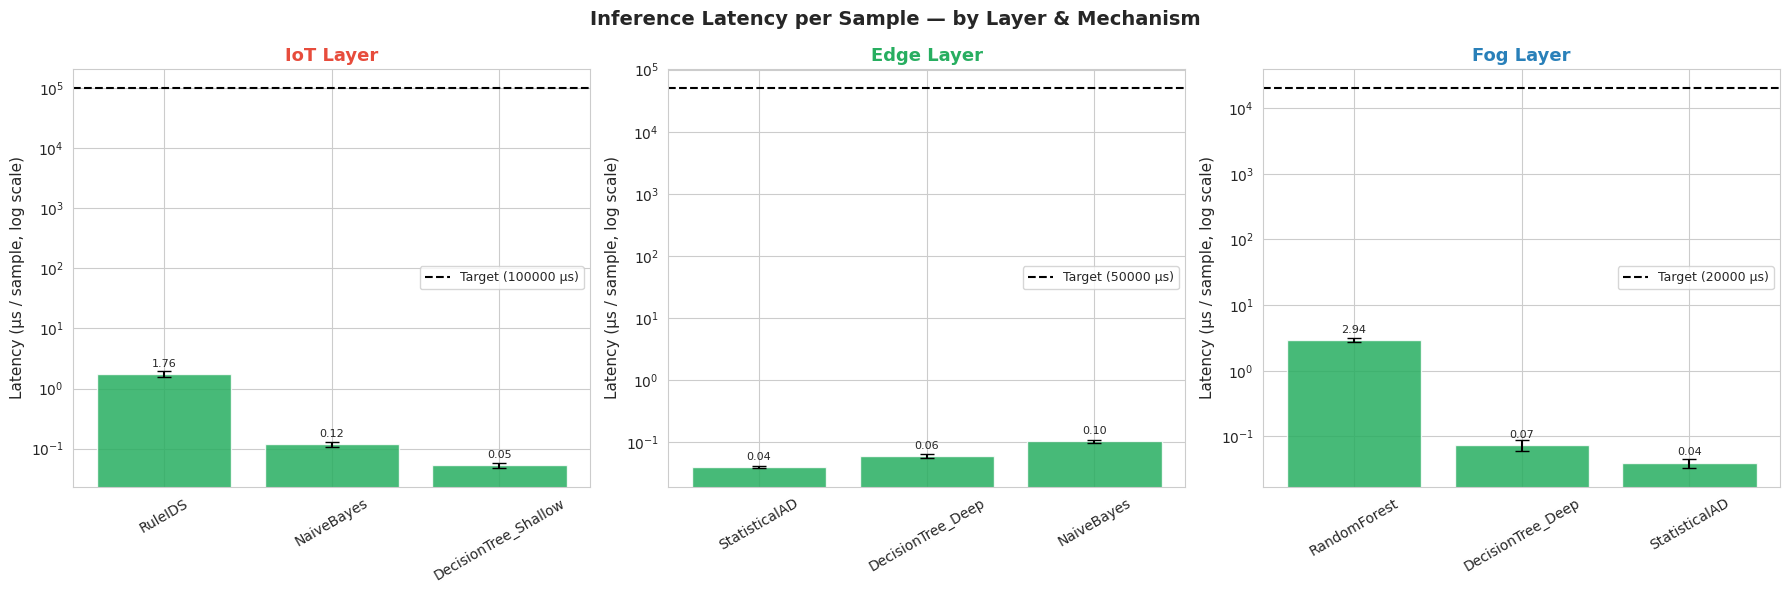

In [ ]:
# Plot 1: Inference Latency
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (layer, mechs) in zip(axes, all_results.items()):
    names  = list(mechs.keys())
    lats   = [m['latency_us_per_sample'] for m in mechs.values()]
    stds   = [m['latency_std_us']        for m in mechs.values()]
    target = LAYER_PROFILES[layer]['latency_target_ms'] * 1000  # µs

    bar_colors = ['#27AE60' if l <= target else '#E74C3C' for l in lats]
    bars = ax.bar(names, lats, yerr=stds, color=bar_colors, alpha=0.85,
                  edgecolor='white', capsize=5)

    ax.set_yscale('log')  # latencies (≈0.05–2 µs) and target (tens of thousands of µs)
                           # differ by orders of magnitude — log scale keeps both visible

    ax.axhline(target, color='black', ls='--', lw=1.5, label=f'Target ({target:.0f} µs)')
    ax.set_title(f'{layer} Layer', fontweight='bold', color=LAYER_PROFILES[layer]['color'])
    ax.set_ylabel('Latency (µs / sample, log scale)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=9)

    for bar, v in zip(bars, lats):
        # multiplicative offset for label placement on a log axis
        ax.text(bar.get_x() + bar.get_width()/2, v * 1.3,
                 f'{v:.2f}', ha='center', fontsize=8)

plt.suptitle('Inference Latency per Sample — by Layer & Mechanism',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('latency_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


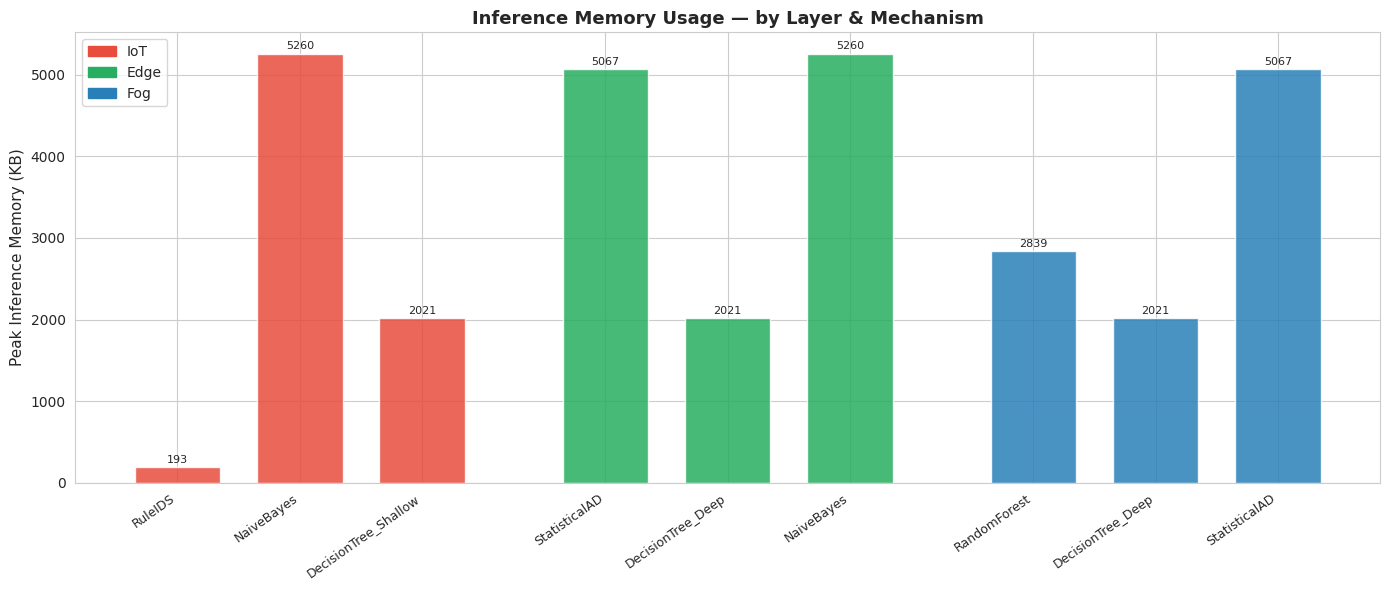

In [ ]:
# Plot 2: Memory Usage
fig, ax = plt.subplots(figsize=(14, 6))
x_pos, xticks, bar_info = 0, [], []

for layer, mechs in all_results.items():
    start = x_pos
    for mname, mres in mechs.items():
        bar = ax.bar(x_pos, mres['infer_mem_kb'],
                     color=LAYER_PROFILES[layer]['color'], alpha=0.85,
                     edgecolor='white', width=0.7)
        ax.text(x_pos, mres['infer_mem_kb'] + max(
            m['infer_mem_kb'] for l in all_results.values() for m in l.values()
        ) * 0.01, f"{mres['infer_mem_kb']:.0f}", ha='center', fontsize=8)
        bar_info.append((x_pos, mname))
        x_pos += 1
    xticks.append(((start + x_pos - 1) / 2, layer))
    x_pos += 0.5

ax.set_xticks([p for p, _ in bar_info])
ax.set_xticklabels([n for _, n in bar_info], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Peak Inference Memory (KB)')
ax.set_title('Inference Memory Usage — by Layer & Mechanism', fontsize=13, fontweight='bold')
ax.legend(handles=[mpatches.Patch(color=LAYER_PROFILES[l]['color'], label=l) for l in LAYER_PROFILES])
plt.tight_layout()
plt.savefig('memory_usage.png', dpi=150, bbox_inches='tight')
plt.show()


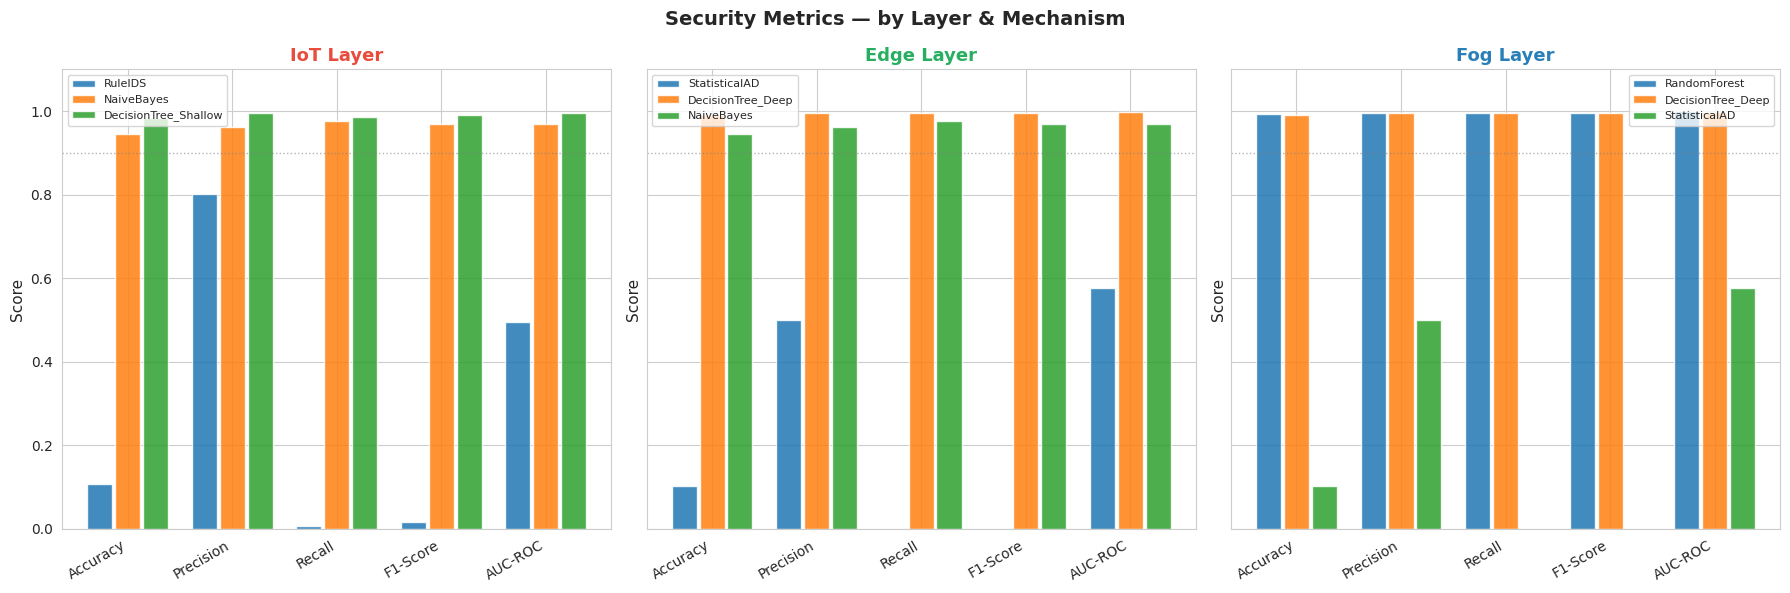

In [ ]:
# Plot 3: Security Metrics Grouped Bar
metrics_keys   = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, (layer, mechs) in zip(axes, all_results.items()):
    n = len(mechs)
    x = np.arange(len(metrics_keys))
    w = 0.8 / n
    for i, (mname, mres) in enumerate(mechs.items()):
        vals   = [mres[m] for m in metrics_keys]
        offset = (i - n/2 + 0.5) * w
        ax.bar(x + offset, vals, w * 0.9, label=mname, alpha=0.85, edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_labels, rotation=30, ha='right')
    ax.set_ylim(0, 1.1)
    ax.axhline(0.9, color='gray', ls=':', lw=1, alpha=0.6)
    ax.set_title(f'{layer} Layer', fontweight='bold', color=LAYER_PROFILES[layer]['color'])
    ax.set_ylabel('Score')
    ax.legend(fontsize=8)

plt.suptitle('Security Metrics — by Layer & Mechanism', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('security_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


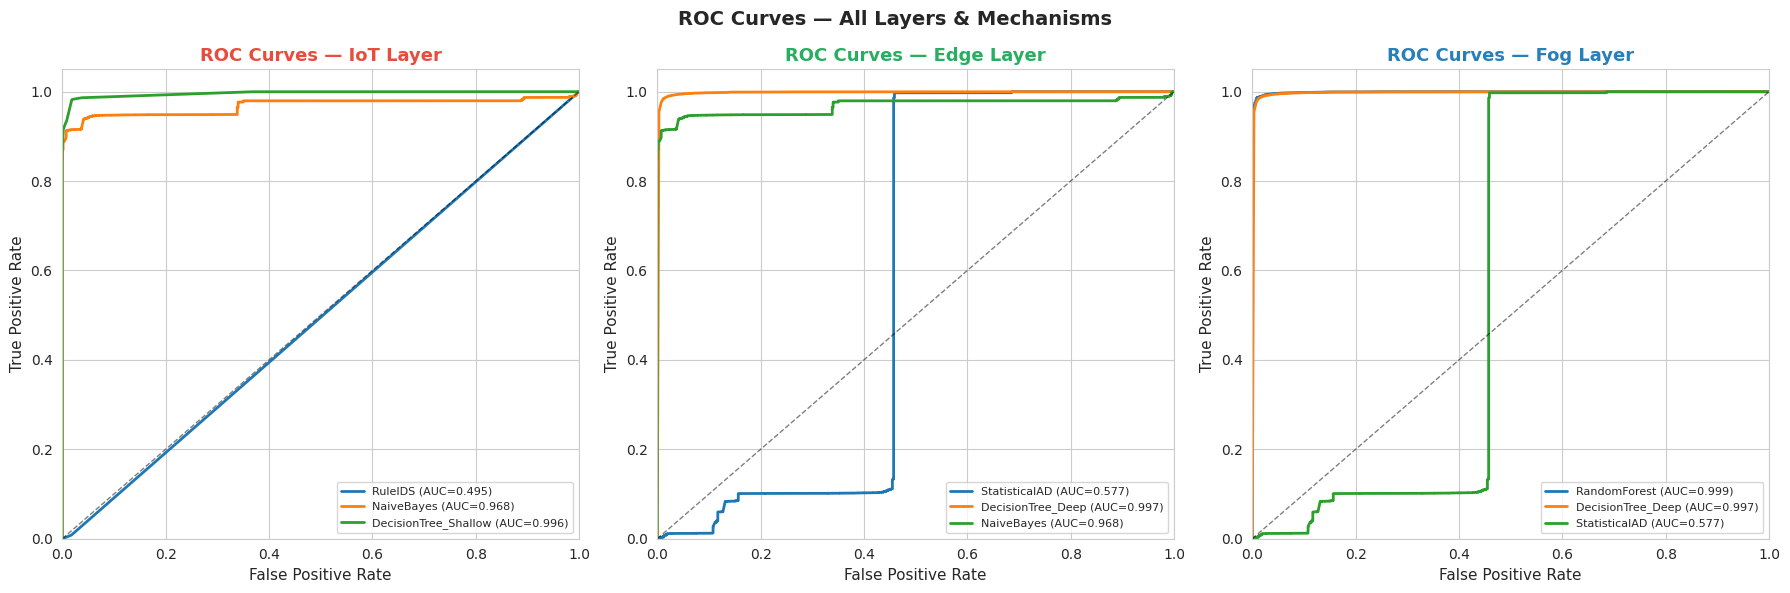

In [ ]:
# Plot 4: ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (layer, mechs) in zip(axes, all_results.items()):
    for mname, mres in mechs.items():
        fpr, tpr, _ = roc_curve(mres['y_test'], mres['y_proba'])
        ax.plot(fpr, tpr, lw=2, label=f"{mname} (AUC={mres['auc_roc']:.3f})")
    ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC Curves — {layer} Layer', fontweight='bold',
                 color=LAYER_PROFILES[layer]['color'])
    ax.legend(fontsize=8, loc='lower right')
    ax.set_xlim([0,1]); ax.set_ylim([0,1.05])

plt.suptitle('ROC Curves — All Layers & Mechanisms', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()


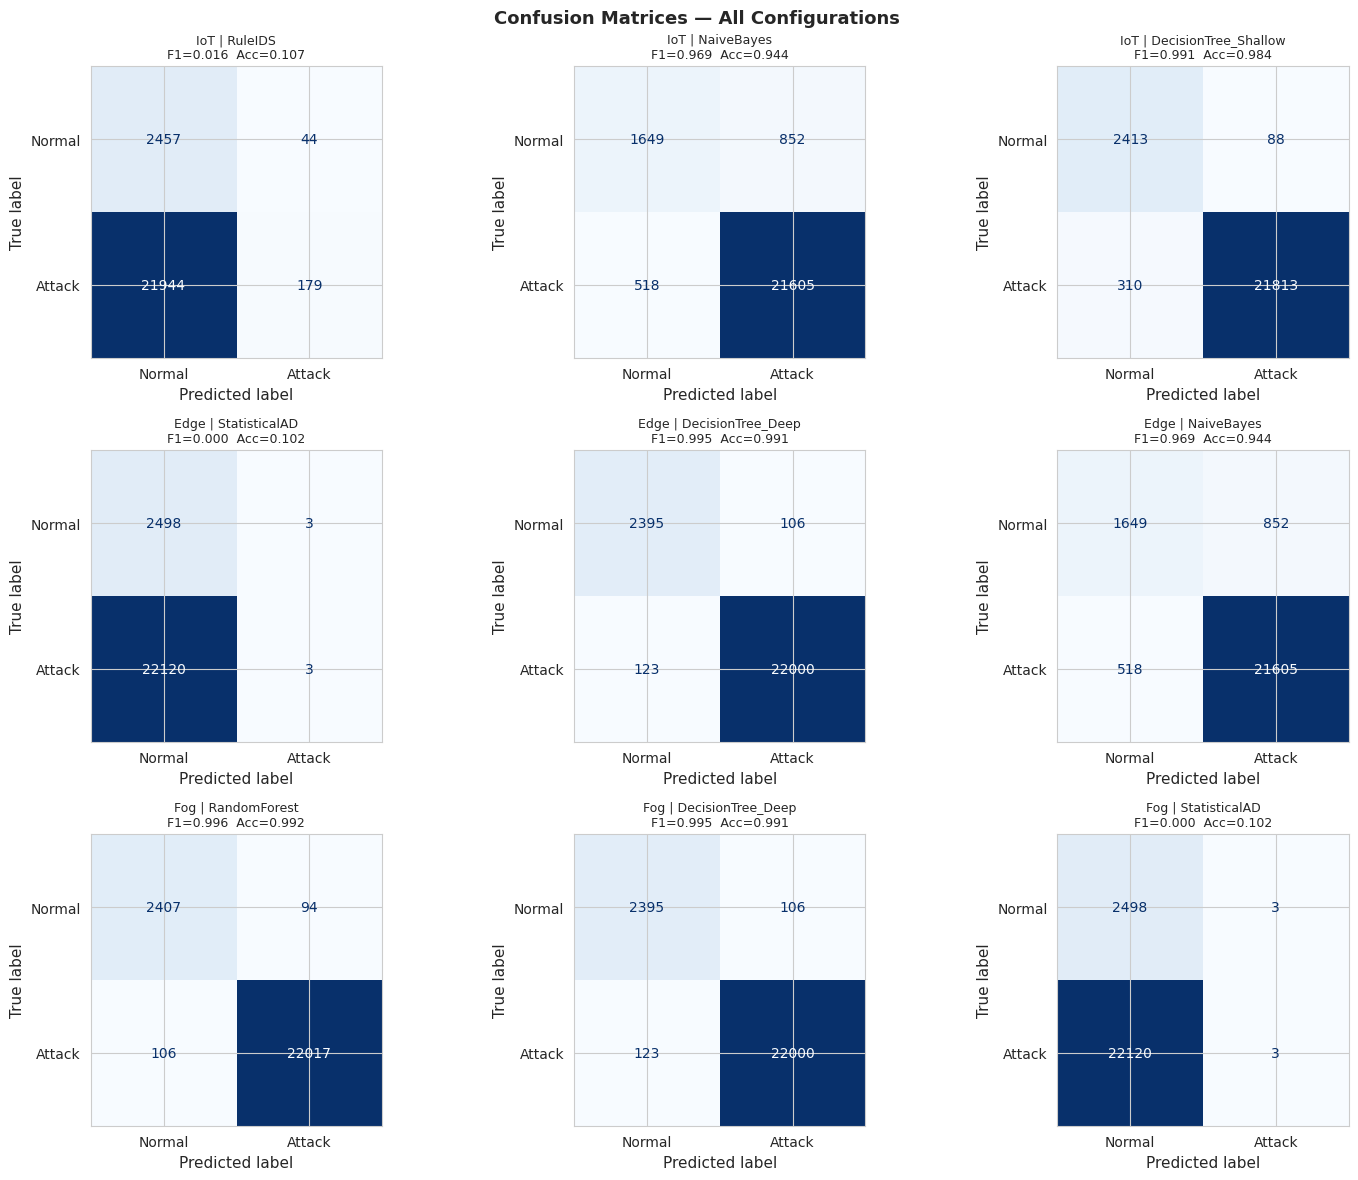

In [ ]:
# Plot 5: Confusion Matrix Grid
configs  = [(l, mn, mr) for l, mechs in all_results.items() for mn, mr in mechs.items()]
n_cols   = 3
n_rows   = (len(configs) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*4))
axes_flat = axes.flatten()

for i, (layer, mname, mres) in enumerate(configs):
    cm = confusion_matrix(mres['y_test'], mres['y_pred'])
    ConfusionMatrixDisplay(cm, display_labels=['Normal','Attack']).plot(
        ax=axes_flat[i], colorbar=False, cmap='Blues')
    axes_flat[i].set_title(
        f'{layer} | {mname}\nF1={mres["f1"]:.3f}  Acc={mres["accuracy"]:.3f}', fontsize=9)

for j in range(i+1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('Confusion Matrices — All Configurations', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


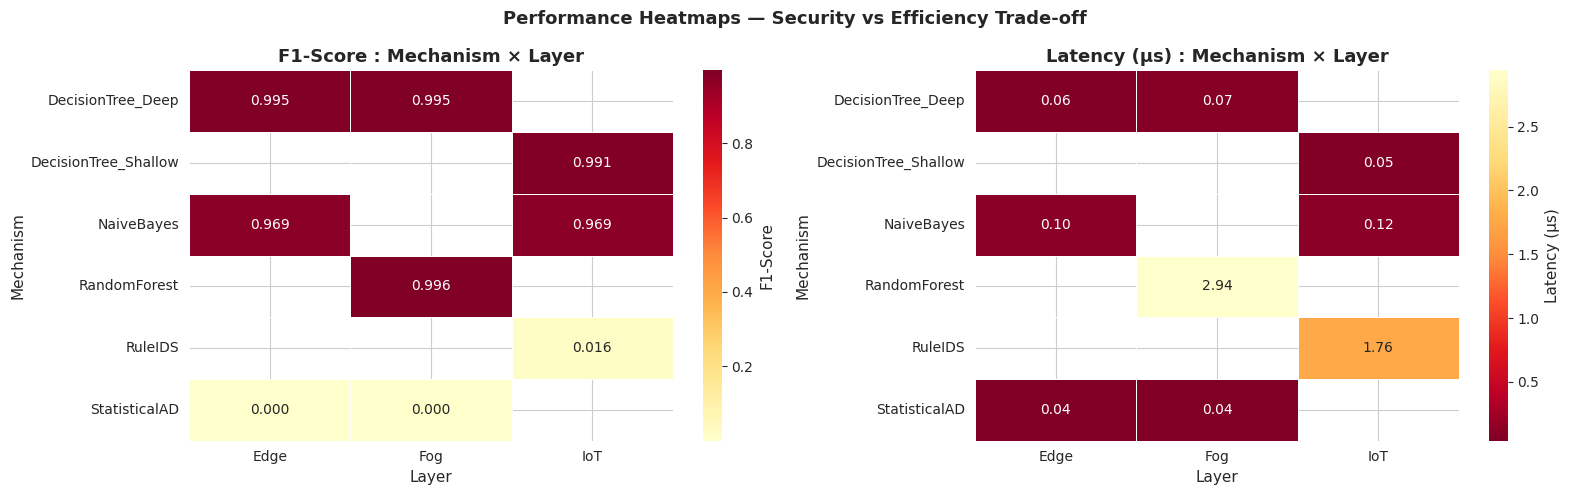

In [ ]:
# Plot 6: Performance Heatmaps
records = [
    {'Layer': l, 'Mechanism': mn,
     'F1-Score': mr['f1'], 'AUC-ROC': mr['auc_roc'],
     'Latency (µs)': mr['latency_us_per_sample'],
     'Memory (KB)': mr['infer_mem_kb']}
    for l, mechs in all_results.items() for mn, mr in mechs.items()
]
results_df = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, metric, cmap in zip(axes,
    ['F1-Score', 'Latency (µs)'],
    ['YlOrRd',   'YlOrRd_r']):
    pivot = results_df.pivot(index='Mechanism', columns='Layer', values=metric)
    fmt   = '.3f' if 'F1' in metric else '.2f'
    sns.heatmap(pivot, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                linewidths=0.5, cbar_kws={'label': metric})
    ax.set_title(f'{metric} : Mechanism × Layer', fontweight='bold')

plt.suptitle('Performance Heatmaps — Security vs Efficiency Trade-off',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('performance_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


## Section 10: Results Summary & Download

In [ ]:
# Full results table
rows = []
for layer, mechs in all_results.items():
    for mname, mr in mechs.items():
        lat_ok = mr['latency_us_per_sample'] <= LAYER_PROFILES[layer]['latency_target_ms'] * 1000
        rows.append({
            'Layer'          : layer,
            'Mechanism'      : mname,
            'Accuracy'       : f"{mr['accuracy']:.3f}",
            'Precision'      : f"{mr['precision']:.3f}",
            'Recall'         : f"{mr['recall']:.3f}",
            'F1-Score'       : f"{mr['f1']:.3f}",
            'AUC-ROC'        : f"{mr['auc_roc']:.3f}",
            'Latency (µs)'   : f"{mr['latency_us_per_sample']:.2f}",
            'Memory (KB)'    : f"{mr['infer_mem_kb']:.1f}",
            'Train (ms)'     : f"{mr['train_time_ms']:.1f}",
            'Latency Budget' : 'Within Limit' if lat_ok else 'Exceeds Limit'
        })

summary_df = pd.DataFrame(rows).sort_values(['Layer','F1-Score'], ascending=[True, False])
print("=" * 110)
print("  RESEARCH RESULTS SUMMARY — Lightweight Cybersecurity for the three layers")
print("=" * 110)
print(summary_df.to_string(index=False))
summary_df.to_csv('results_summary.csv', index=False)
print("\nSaved to results_summary.csv")


  RESEARCH RESULTS SUMMARY — Lightweight Cybersecurity for the three layers
Layer            Mechanism Accuracy Precision Recall F1-Score AUC-ROC Latency (µs) Memory (KB) Train (ms) Latency Budget
 Edge    DecisionTree_Deep    0.991     0.995  0.994    0.995   0.997         0.06      2020.9       80.6   Within Limit
 Edge           NaiveBayes    0.944     0.962  0.977    0.969   0.968         0.10      5259.8       29.9   Within Limit
 Edge        StatisticalAD    0.102     0.500  0.000    0.000   0.577         0.04      5066.9        4.4   Within Limit
  Fog         RandomForest    0.992     0.996  0.995    0.996   0.999         2.94      2838.7     2271.1   Within Limit
  Fog    DecisionTree_Deep    0.991     0.995  0.994    0.995   0.997         0.07      2020.9       75.2   Within Limit
  Fog        StatisticalAD    0.102     0.500  0.000    0.000   0.577         0.04      5066.9        3.5   Within Limit
  IoT DecisionTree_Shallow    0.984     0.996  0.986    0.991   0.996        

In [ ]:
# Best mechanism per layer
print("\n" + "="*65)
print("  BEST MECHANISM PER LAYER  (ranked by F1-Score)")
print("="*65)
for layer, mechs in all_results.items():
    name, mr = max(mechs.items(), key=lambda x: x[1]['f1'])
    target   = LAYER_PROFILES[layer]['latency_target_ms'] * 1000
    ok       = 'Within budget' if mr['latency_us_per_sample'] <= target else 'Exceeds budget'
    print(f"\n  [{layer:4s}] Best: {name}")
    print(f"         F1={mr['f1']:.3f}  AUC={mr['auc_roc']:.3f}  "
          f"Lat={mr['latency_us_per_sample']:.2f}µs {ok}")
    print(f"         Inference mem: {mr['infer_mem_kb']:.1f} KB")



  BEST MECHANISM PER LAYER  (ranked by F1-Score)

  [IoT ] Best: DecisionTree_Shallow
         F1=0.991  AUC=0.996  Lat=0.05µs Within budget
         Inference mem: 2020.9 KB

  [Edge] Best: DecisionTree_Deep
         F1=0.995  AUC=0.997  Lat=0.06µs Within budget
         Inference mem: 2020.9 KB

  [Fog ] Best: RandomForest
         F1=0.996  AUC=0.999  Lat=2.94µs Within budget
         Inference mem: 2838.7 KB


In [ ]:
# Download all outputs as ZIP
output_files = [
    'results_summary.csv',
    'class_distribution.png',   'correlation_heatmap.png',
    'traffic_behaviour.png',    'feature_importance.png',
    'latency_comparison.png',   'memory_usage.png',
    'security_metrics.png',     'roc_curves.png',
    'confusion_matrices.png',   'performance_heatmap.png'
]

with zipfile.ZipFile('research_outputs.zip', 'w') as zf:
    for f in output_files:
        if os.path.exists(f):
            zf.write(f); print(f" {f}")
        else:
            print(f"Not yet generated: {f}")

from google.colab import files
files.download('research_outputs.zip')
print("research_outputs.zip downloaded")


 results_summary.csv
 class_distribution.png
 correlation_heatmap.png
 traffic_behaviour.png
 feature_importance.png
 latency_comparison.png
 memory_usage.png
 security_metrics.png
 roc_curves.png
 confusion_matrices.png
 performance_heatmap.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

research_outputs.zip downloaded
